# Day 5 · Demo 1: regression as a generative model

Bayesian statistics for PhD researchers, Aalborg University 2026. This notebook reproduces the figures of the **Day 5 morning slides**. Each section names its slide. Run it with the **R (bayes)** kernel from the `demos/` folder.

The data are the slides' **illustrative** time-game data: one person, 30 attempts, ten each at targets of 5, 10 and 15 seconds, without feedback. No model is fitted here: the morning is about what the model says **before** it sees the data. The fit is in Demo 2.

In [1]:
options(tidyverse.quiet = TRUE)
library(tidyverse)   # dplyr for summaries, ggplot2 for figures
library(cmdstanr)    # Stan from R
set.seed(2026)
options(width = 95, repr.plot.width = 8, repr.plot.height = 5, repr.plot.bg = "white")
theme_set(theme_minimal(base_size = 14) + theme(legend.position = "top"))

d <- read_csv("data/slides-one-person.csv", show_col_types = FALSE)   # attempt, target_seconds, recorded_seconds
d <- d |> mutate(x = target_seconds - 10)                              # centred predictor
d |> group_by(target_seconds) |> summarise(attempts = n(), mean = mean(recorded_seconds), sd = sd(recorded_seconds))

This is cmdstanr version 0.9.0

- CmdStanR documentation and vignettes: mc-stan.org/cmdstanr

- CmdStan path: /opt/homebrew/Caskroom/miniconda/base/envs/bayes/bin/cmdstan

- CmdStan version: 2.40.0



target_seconds,attempts,mean,sd
<dbl>,<int>,<dbl>,<dbl>
5,10,5.388,0.3302121
10,10,9.731,0.9771324
15,10,14.298,1.3952204


## 1. Does her clock scale?

*Slide "Does her clock scale?".* Each point is one attempt. The dashed line is perfect timing: recorded time = target.

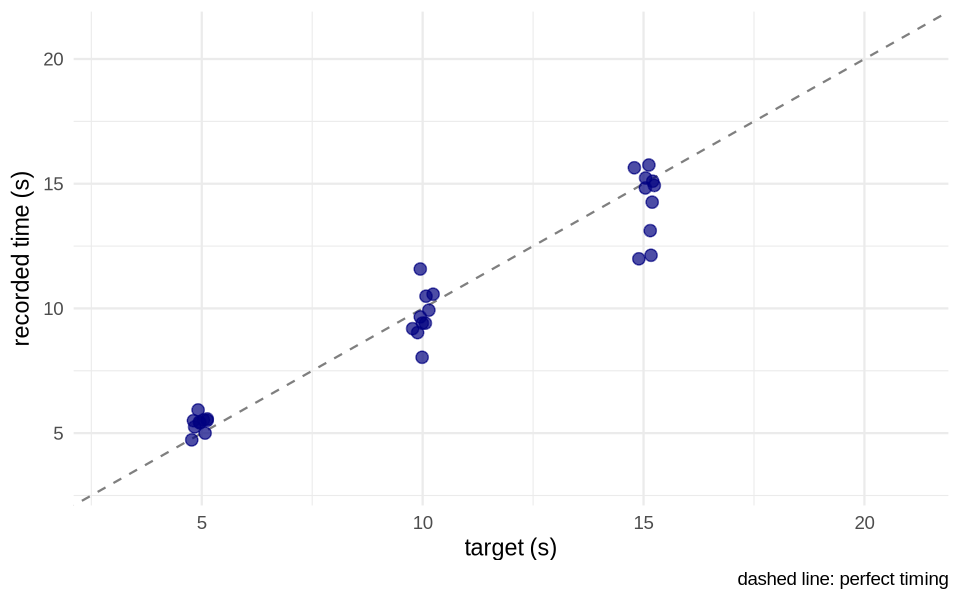

In [2]:
ggplot(d, aes(x = target_seconds, y = recorded_seconds)) +
  geom_abline(intercept = 0, slope = 1, linetype = "dashed", colour = "grey50") +
  geom_jitter(width = 0.25, height = 0, size = 3, alpha = 0.7, colour = "navy") +
  coord_cartesian(xlim = c(3, 21), ylim = c(3, 21)) +
  labs(x = "target (s)", y = "recorded time (s)", caption = "dashed line: perfect timing")

## 2. Regression: a model that generates the data

*Slide "Regression: a model that generates the data".* The model

yᵢ ~ Normal(α + β · xᵢ, σ), independent given x.

To **generate** data from it: pick values of α, β and σ, compute the mean α + β · x for each attempt, and draw y around that mean with SD σ. Here with α = 9.8, β = 0.9, σ = 0.9.

attempt,target_seconds,recorded_seconds,x,mean_line,y_sim
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,5,5.50,-5,5.3,4.328278
2,5,4.73,-5,5.3,5.425314
3,5,5.51,-5,5.3,5.223726
4,5,5.00,-5,5.3,4.700024
5,5,5.45,-5,5.3,3.035520
6,5,5.93,-5,5.3,4.638368


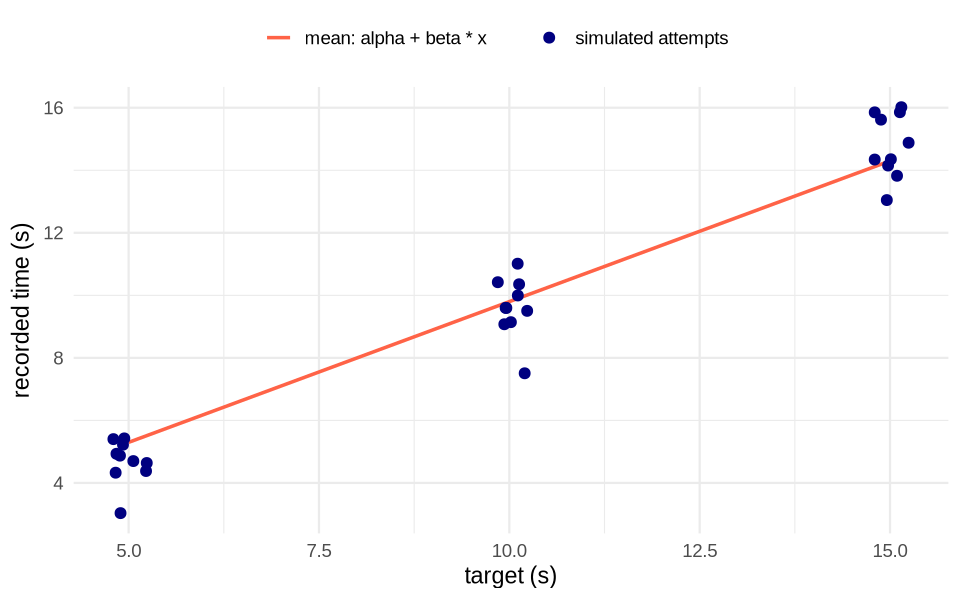

In [3]:
alpha <- 9.8; beta <- 0.9; sigma <- 0.9
simulated <- d |> mutate(mean_line = alpha + beta * x,
                         y_sim     = rnorm(n(), mean_line, sigma))
head(simulated)

ggplot(simulated, aes(x = target_seconds)) +
  geom_line(aes(y = mean_line, colour = "mean: alpha + beta * x"), linewidth = 1) +
  geom_jitter(aes(y = y_sim, colour = "simulated attempts"), width = 0.25, height = 0, size = 2.5) +
  scale_colour_manual(values = c("mean: alpha + beta * x" = "tomato", "simulated attempts" = "navy"), name = NULL) +
  labs(x = "target (s)", y = "recorded time (s)")

## 3. Choose a scale for x

*Slide "Choose a scale for x".* With x = target, α would be her mean recorded time at a target of 0 s, which is never observed. With x = target − 10, α is her mean at the 10-s target, in the middle of the data. Below: the same line, and where α sits in each case.

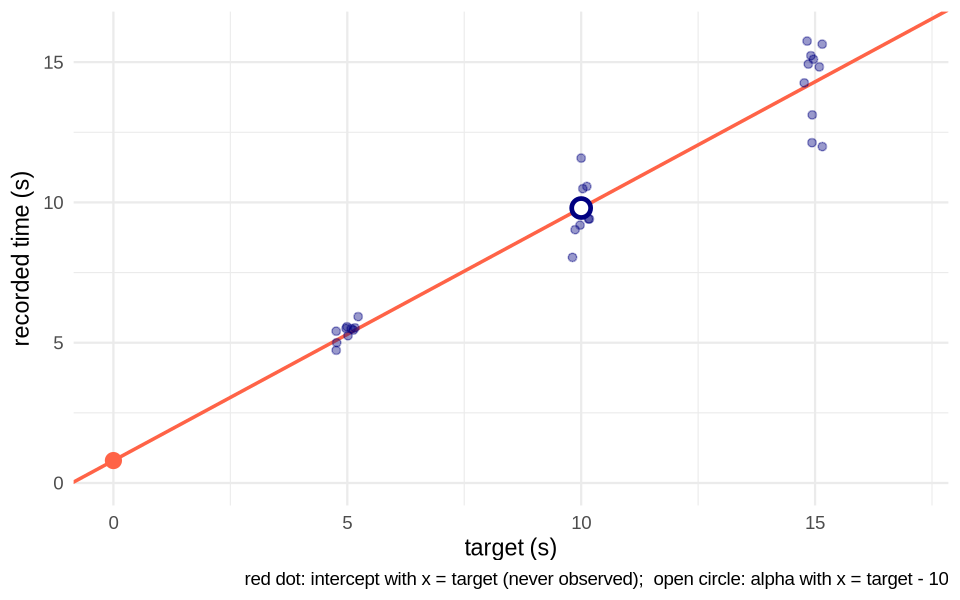

In [4]:
ggplot(d, aes(x = target_seconds, y = recorded_seconds)) +
  geom_abline(intercept = alpha - 10 * beta, slope = beta, colour = "tomato", linewidth = 1) +
  geom_jitter(width = 0.25, height = 0, alpha = 0.4, colour = "navy") +
  annotate("point", x = 0,  y = alpha - 10 * beta, size = 4, colour = "tomato") +
  annotate("point", x = 10, y = alpha, size = 4, shape = 21, fill = "white", colour = "navy", stroke = 2) +
  coord_cartesian(xlim = c(0, 17), ylim = c(0, 16)) +
  labs(x = "target (s)", y = "recorded time (s)",
       caption = "red dot: intercept with x = target (never observed);  open circle: alpha with x = target - 10")

## 4. Prior predictive simulation

*Slides "Priors on that scale" and "Prior predictive simulation".* The priors

α ~ Normal(10, 2),  β ~ Normal(1, 0.5),  σ ~ Normal⁺(0, 2).

No data are used. Draw α, β and σ from their priors, compute the mean at a target, draw attempts around it, and look at the recorded times the model expects.

In [5]:
S <- 4000
prior <- tibble(alpha = rnorm(S, 10, 2),
                beta  = rnorm(S, 1, 0.5),
                sigma = abs(rnorm(S, 0, 2)))     # half-normal: keep the positive side

# one simulated attempt per prior draw, at each of four targets
prior_pred <- prior |>
  cross_join(tibble(target = c(5, 10, 15, 20))) |>
  mutate(y_sim = rnorm(n(), alpha + beta * (target - 10), sigma))

prior_pred |> group_by(target) |>
  summarise(q5 = quantile(y_sim, 0.05), q95 = quantile(y_sim, 0.95), share_negative = mean(y_sim < 0))

target,q5,q95,share_negative
<dbl>,<dbl>,<dbl>,<dbl>
5,-1.378374,11.27947,0.09525
10,5.562631,14.49174,0.00125
15,8.997949,21.00907,0.00075
20,10.623238,29.65648,0.00025


## 5. What the prior predicts

*Slide "What the prior predicts".* Each line is the mean α + β · x for one prior draw. Left: the priors above. Right: a "vague" prior α ~ Normal(0, 20), β ~ Normal(0, 10).

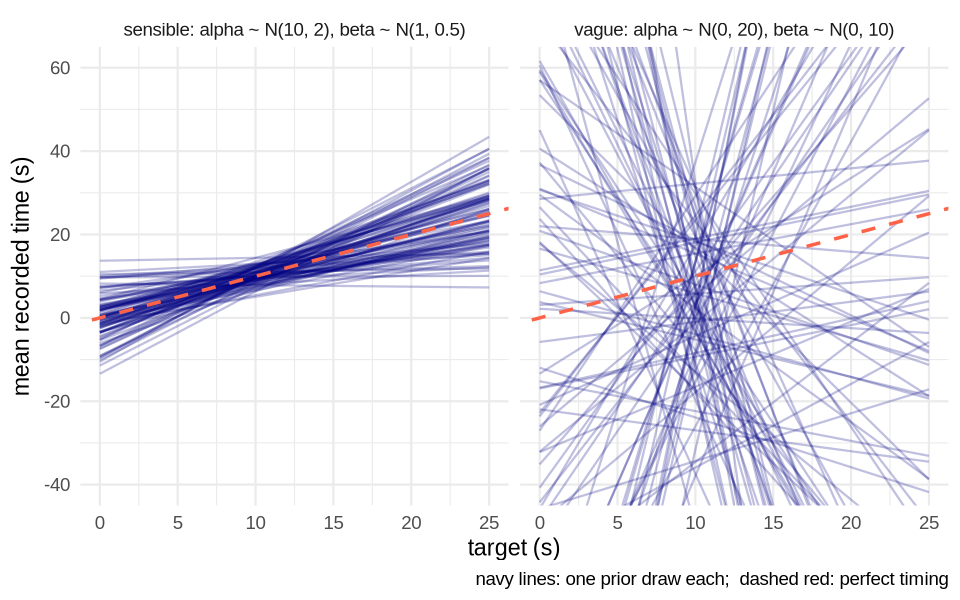

In [6]:
n_lines <- 100
prior_lines <- bind_rows(
    tibble(prior = "sensible: alpha ~ N(10, 2), beta ~ N(1, 0.5)", draw = 1:n_lines,
           alpha = rnorm(n_lines, 10, 2), beta = rnorm(n_lines, 1, 0.5)),
    tibble(prior = "vague: alpha ~ N(0, 20), beta ~ N(0, 10)", draw = 1:n_lines,
           alpha = rnorm(n_lines, 0, 20), beta = rnorm(n_lines, 0, 10))) |>
  cross_join(tibble(target = seq(0, 25, by = 0.5))) |>
  mutate(mean_line = alpha + beta * (target - 10))

ggplot(prior_lines, aes(x = target, y = mean_line, group = draw)) +
  geom_line(alpha = 0.25, colour = "navy") +
  geom_abline(intercept = 0, slope = 1, linetype = "dashed", colour = "tomato", linewidth = 1) +
  facet_wrap(~ prior) + coord_cartesian(ylim = c(-40, 60)) +
  labs(x = "target (s)", y = "mean recorded time (s)",
       caption = "navy lines: one prior draw each;  dashed red: perfect timing")

## 6. Fake data from the prior

*Slide "Fake data from the prior".* Six complete datasets, each from one prior draw of (α, β, σ), at the same 30 targets as her real data. Do they look like recorded times?

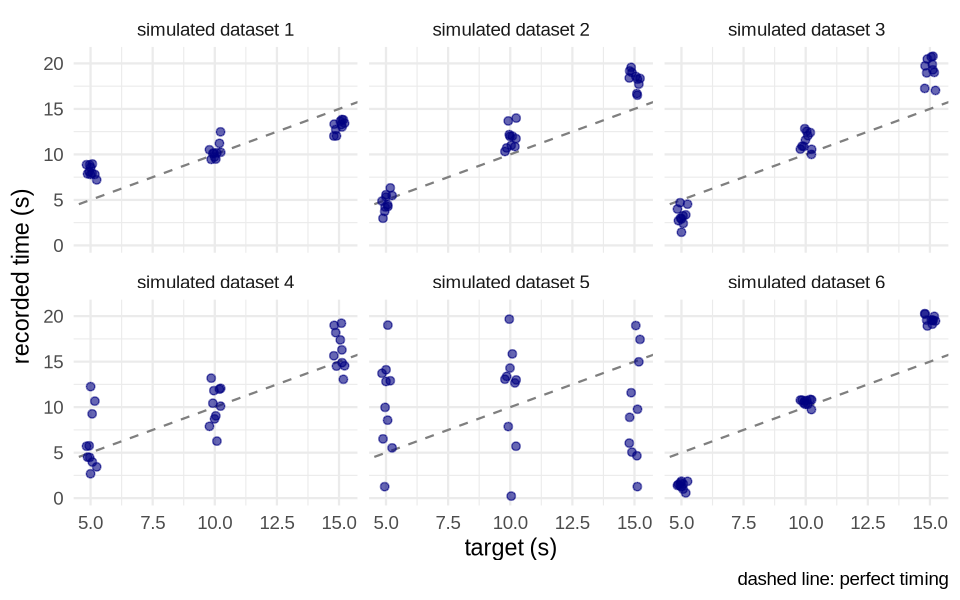

In [7]:
fake <- tibble(dataset = paste("simulated dataset", 1:6),
               alpha = rnorm(6, 10, 2), beta = rnorm(6, 1, 0.5), sigma = abs(rnorm(6, 0, 2))) |>
  cross_join(d |> select(target_seconds, x)) |>
  mutate(y_sim = rnorm(n(), alpha + beta * x, sigma))

ggplot(fake, aes(x = target_seconds, y = y_sim)) +
  geom_abline(intercept = 0, slope = 1, linetype = "dashed", colour = "grey50") +
  geom_jitter(width = 0.25, height = 0, alpha = 0.6, colour = "navy") +
  facet_wrap(~ dataset, nrow = 2) +
  labs(x = "target (s)", y = "recorded time (s)", caption = "dashed line: perfect timing")

## 7. The regression in Stan

*Slide "The regression in Stan".* The program the afternoon fits. We print it and compile it here, so that the compilation (about a minute) is done before the afternoon.

In [8]:
writeLines(readLines("models/regression.stan"))
mod <- cmdstan_model("models/regression.stan")

// Linear regression: recorded time against target time
data {
  int<lower=1> N;
  vector[N] x;                 // target - 10 (seconds)
  vector[N] y;                 // recorded time (seconds)
}
parameters {
  real alpha;                  // mean recorded time at target 10 s
  real beta;                   // extra recorded seconds per extra target second
  real<lower=0> sigma;         // spread around the line
}
model {
  alpha ~ normal(10, 2);
  beta ~ normal(1, 0.5);
  sigma ~ normal(0, 2);
  y ~ normal(alpha + beta * x, sigma);
}
generated quantities {
  real mu_20 = alpha + beta * 10;          // mean recorded time at target 20 s
  real y_20 = normal_rng(mu_20, sigma);    // one attempt at target 20 s
  array[N] real y_rep = normal_rng(alpha + beta * x, sigma);  // a replicated dataset
}


The data list passes the **centred** predictor x = target − 10:

In [9]:
stan_data <- list(N = nrow(d), x = d$x, y = d$recorded_seconds)
str(stan_data)

List of 3
 $ N: int 30
 $ x: num [1:30] -5 -5 -5 -5 -5 -5 -5 -5 -5 -5 ...
 $ y: num [1:30] 5.5 4.73 5.51 5 5.45 5.93 5.25 5.41 5.57 5.53 ...
